# 01 Data understanding (PEMS-BAY)

Run the sections in order. **Part A** inspects the raw files (Day 2). **Part B** checks the hourly table
that `src/01_build_dataset.py` produced (Day 5). Everything saved to `results/data_quality/` feeds the
website's Data page. Write your own one-line conclusion under each check.

In [1]:
import json, os, sys
from pathlib import Path

# Work from the repository root whether the notebook is opened from notebooks/ or the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

cfg = json.load(open("configs/dataset.json"))
OUT = Path("results/data_quality"); OUT.mkdir(parents=True, exist_ok=True)
cfg

{'dataset_name': 'PEMS-BAY',
 'speed_file': 'data/raw/pems-bay.h5',
 'speed_key': None,
 'sensor_locations_file': 'data/raw/graph_sensor_locations_bay.csv',
 'min_coverage': 0.95,
 'min_readings_per_hour': 9,
 'n_segments': 8,
 'n_neighbours': 3,
 'segments': ['401507',
  '404554',
  '400414',
  '400100',
  '402287',
  '413878',
  '407157',
  '407176'],
 'city_name': 'San Francisco Bay Area',
 'city_lat': None,
 'city_lon': None,
 'timezone': 'America/Los_Angeles',
 'holiday_country': 'US',
 'holiday_subdiv': 'CA'}

## Part A: raw files
### A1. HDF5 keys, shape, time range

### Part A, Day 2 checks on the raw files
Each check: code, output, then a note (what I saw → what it means).

In [2]:
import pandas as pd, numpy as np
p = "data/raw/pems-bay.h5"
q = "data/raw/graph_sensor_locations_bay.csv"

In [3]:
with pd.HDFStore(p) as s: print(s.keys())

['/speed']


**Keys.** The file holds one table, key `speed`.

In [4]:
df = pd.read_hdf(p, key="speed")
print(df.shape, df.dtypes.unique())
df.iloc[:3, :4]

(52116, 325) [dtype('float64')]


sensor_id,400001,400017,400030,400040
2017-01-01 00:00:00,71.4,67.8,70.5,67.4
2017-01-01 00:05:00,71.6,67.5,70.6,67.5
2017-01-01 00:10:00,71.6,67.6,70.2,67.4


**Shape.** 52,116 rows × 325 columns, all float64. Rows are 5-minute timestamps, columns are sensors (wide format).

In [5]:
# pandas 2.3 + pytables: the stored index freq loads as bytes and breaks printing a Series,
# so rebuild a plain DatetimeIndex first.
ts = pd.Series(pd.DatetimeIndex(df.index.values))
print(ts.min(), ts.max())
d = ts.diff()
print(d.value_counts().head())
gap = d[d > pd.Timedelta("5min")]
pd.DataFrame({"before": ts.shift()[gap.index], "after": ts[gap.index], "gap": gap})

2017-01-01 00:00:00 2017-06-30 23:55:00
0 days 00:05:00    52114
0 days 01:05:00        1
Name: count, dtype: int64


C:\Users\shrey\AppData\Local\Temp\ipykernel_23224\3166125400.py:7: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  gap = d[d > pd.Timedelta("5min")]


,before,after,gap
20184,2017-03-12 01:55:00,2017-03-12 03:00:00,0 days 01:05:00


**Time range and gaps.** 2017-01-01 00:00 to 2017-06-30 23:55. 52,114 steps are exactly 5 min and there is one jump of 1h05m, 2017-03-12 01:55 → 03:00 (so 02:00–02:55 is absent).

181 days × 288 = 52,128 expected; we have 52,116; 12 missing = 1 hour. That is the US DST spring-forward, so the timestamps are **local time**, not UTC.

In [6]:
print("zero share:", (df == 0).mean().mean())
print("NaN share :", df.isna().mean().mean())

zero share: 3.075978438630983e-05
NaN share : 0.0


**Missing encoding.** Missing is marked as **zero**, not NaN (NaN share is exactly 0). Zero share is about 0.003% (3e-05, roughly 521 readings out of 16.9M). I convert zeros to NaN before averaging, because a 0 mph reading would drag hourly means down falsely.

In [7]:
z = (df.iloc[:, 0] == 0)
runs = z.ne(z.shift()).cumsum()[z].value_counts()
print("sensor 0 longest zero run (5-min steps):", runs.max())
share_zero = (df == 0).mean(axis=1)
print("max share of sensors at zero in one timestamp:", share_zero.max())
share_zero[share_zero > 0.05]

sensor 0 longest zero run (5-min steps): 1
max share of sensors at zero in one timestamp: 0.6676923076923077


2017-04-20 01:40:00    0.280000
2017-05-05 19:55:00    0.249231
2017-05-09 20:35:00    0.406154
2017-06-15 01:00:00    0.667692
dtype: float64

**Zero runs.** Sensor 0's longest zero run is 1 step, so it has isolated glitches rather than long outages. But at one timestamp (2017-06-15 01:00) 67% of sensors read zero together, and three other moments (04-20, 05-05, 05-09) have 25–41%. Many sensors at zero at once is a feed outage, not a real jam; real traffic does not hit exactly 0 on two thirds of a freeway network. These are rare (4 timestamps above 5%), so the zero→NaN rule covers them.

In [8]:
v = df.replace(0, np.nan)
print(v.stack().describe())

count    1.693718e+07
mean     6.262150e+01
std      9.588231e+00
min      3.000000e+00
25%      6.210000e+01
50%      6.530000e+01
75%      6.750000e+01
max      8.510000e+01
dtype: float64


**Units.** After removing zeros: min 3, mean ≈ 62.6, max ≈ 85. That is the freeway speed-limit range, so values are **mph**. Converted ×1.609344 to km/h (max ≈ 137 km/h).

In [9]:
loc = pd.read_csv(q, header=None)
print(loc.shape); loc.head()

(325, 3)


,0,1,2
0,400001,37.364085,-121.901149
1,400017,37.253303,-121.945440
2,400030,37.359087,-121.906538
3,400040,37.294949,-121.873109
4,400045,37.363402,-121.902233


**Locations.** 325 rows, 3 columns, no header: sensor id, latitude, longitude. I name the columns myself. One row per speed sensor, so nearest neighbours by distance can be computed.

`adj_mx_bay.pkl` is unused: I build neighbours from lat/lon distance. Limit: straight-line distance is not road connectivity (two close sensors can be on opposite carriageways or different roads).

**Part A summary**

* Data: PEMS-BAY, 325 sensors, 5-min, Jan–Jun 2017, mph.
* Missing rule: missing is stored as 0 (NaN share = 0, zero share ≈ 0.003%); zeros become NaN, and simultaneous zeros across sensors are feed outages.
* Why hourly: the target is hourly, and averaging 12 readings cuts noise.
* Why 8 segments: explainable, ≥95% coverage, frozen before modelling.
* Units are km/h (converted from mph); timestamps are local time (the DST gap proves it).

In [10]:
from load_raw import list_keys, load_speed_wide, load_speed_table, read_sensor_locations
from hourly import to_hourly_wide

keys = list_keys(cfg["speed_file"])
print("HDF5 keys:", keys)
key = cfg["speed_key"] or keys[0]
raw = pd.read_hdf(cfg["speed_file"], key=key)
print("shape (timestamps x sensors):", raw.shape)
print("time range:", raw.index.min(), "->", raw.index.max())
print("step between rows:\n", raw.index.to_series().diff().value_counts().head())
raw.iloc[:5, :5]

HDF5 keys: ['/speed']
shape (timestamps x sensors): (52116, 325)
time range: 2017-01-01 00:00:00 -> 2017-06-30 23:55:00
step between rows:
 0 days 00:05:00    52114
0 days 01:05:00        1
Name: count, dtype: int64


sensor_id,400001,400017,400030,400040,400045
2017-01-01 00:00:00,71.4,67.8,70.5,67.4,68.8
2017-01-01 00:05:00,71.6,67.5,70.6,67.5,68.7
2017-01-01 00:10:00,71.6,67.6,70.2,67.4,68.7
2017-01-01 00:15:00,71.1,67.5,70.3,68.0,68.5
2017-01-01 00:20:00,71.7,67.8,70.2,68.1,68.4


### A2. How are missing values encoded? (zeros in long blocks = outages)

In [11]:
zero_share = (raw == 0).mean()
print("Share of exact-zero readings overall:", round(float((raw == 0).values.mean()), 5))
print("Share of NaN readings overall:", round(float(raw.isna().values.mean()), 5))

def longest_run(mask: pd.Series) -> int:
    runs = mask.ne(mask.shift()).cumsum()
    return int(mask.groupby(runs).sum().max())

longest_zero = raw.apply(lambda c: longest_run(c == 0))
print("Sensors with a zero run longer than 12 steps (1 hour):", int((longest_zero > 12).sum()))
longest_zero.sort_values(ascending=False).head(10)

Share of exact-zero readings overall: 3e-05
Share of NaN readings overall: 0.0
Sensors with a zero run longer than 12 steps (1 hour): 0


sensor_id
414694    1
400001    1
414284    1
407370    1
407367    1
407364    1
407361    1
407360    1
407359    1
407352    1
dtype: int64

If zeros appear in long blocks they are outages, and `load_raw.py` already turns them into NaN. If there are almost none (expected for PEMS-BAY), say so here.

### A3. Sensor location file

In [12]:
locs = read_sensor_locations(cfg["sensor_locations_file"])
print(locs.shape)
print("sensors in the speed file but not in the location file:",
      len(set(map(str, raw.columns)) - set(locs["sensor_id"])))
print("lat range:", locs["latitude"].min(), locs["latitude"].max(),
      "| lon range:", locs["longitude"].min(), locs["longitude"].max())
locs.head()

(325, 3)
sensors in the speed file but not in the location file: 0
lat range: 37.250424 37.427486 | lon range: -122.079539 -121.840267


,sensor_id,latitude,longitude
0,400001,37.364085,-121.901149
1,400017,37.253303,-121.945440
2,400030,37.359087,-121.906538
3,400040,37.294949,-121.873109
4,400045,37.363402,-121.902233


### A4. Long format and units (mph to km/h)

In [13]:
sample_ids = [str(c) for c in raw.columns[:3]]
sample = load_speed_table(cfg["speed_file"], cfg["speed_key"], sensors=sample_ids)
display(sample.head())
print(sample.groupby("segment_id")["speed_kmh"].describe().round(1))
print("Check: raw max (mph) * 1.609344 =", round(float(raw.loc[:, [col for col in raw.columns if str(col) in sample_ids]].max().max()) * 1.609344, 1), "km/h")

,timestamp,segment_id,speed_kmh
0,2017-01-01 00:00:00,400001,114.907162
1,2017-01-01 00:05:00,400001,115.229030
2,2017-01-01 00:10:00,400001,115.229030
3,2017-01-01 00:15:00,400001,114.424358
4,2017-01-01 00:20:00,400001,115.389965


              count   mean   std   min    25%    50%    75%    max
segment_id                                                        
400001      52115.0  108.7  13.1  15.9  108.3  113.1  114.7  129.4
400017      52116.0   95.0  21.3  17.7  100.1  103.0  104.8  115.2
400030      52116.0   95.2  18.8   5.5   89.8  100.9  107.2  125.0
Check: raw max (mph) * 1.609344 = 129.4 km/h


### A5. Hourly build and how many hours were discarded

In [14]:
wide = load_speed_wide(cfg["speed_file"], cfg["speed_key"])
hourly_wide, stats = to_hourly_wide(wide, cfg["min_readings_per_hour"])
print(stats)
print("Share of sensor-hours discarded by the 9-of-12 rule:",
      round(stats["hours_partial_discarded"] / stats["hours_total"], 5))

{'min_readings': 9, 'hours_total': 1411800, 'hours_kept': 1411475, 'hours_no_readings': 325, 'hours_partial_discarded': 0}
Share of sensor-hours discarded by the 9-of-12 rule: 0.0


## Part B: data-quality checks on `data/processed/hourly.parquet` (Guide 7.9)

In [33]:
hourly = pd.read_parquet("data/processed/hourly.parquet")
print(hourly.shape, "| segments:", hourly["segment_id"].nunique())
hourly.head()

(34752, 8) | segments: 8


,timestamp,segment_id,speed_kmh,neighbour_speed_t,temperature,humidity,precipitation,is_holiday
0,2017-01-01 00:00:00,400100,109.086701,109.480096,7.5,71,0.0,1
1,2017-01-01 01:00:00,400100,108.845299,109.189520,4.7,81,0.0,1
2,2017-01-01 02:00:00,400100,108.845299,108.974941,4.7,84,0.0,1
3,2017-01-01 03:00:00,400100,108.684365,108.966000,4.0,86,0.0,1
4,2017-01-01 04:00:00,400100,108.898944,109.752790,5.4,85,0.0,1


### B1. Time range and count per sensor

In [16]:
rng = hourly.groupby("segment_id")["timestamp"].agg(["min", "max", "count"])
rng.to_csv(OUT / "time_range.csv")
rng

,min,max,count
segment_id,,,
400100,2017-01-01,2017-06-30 23:00:00,4344
400414,2017-01-01,2017-06-30 23:00:00,4344
401507,2017-01-01,2017-06-30 23:00:00,4344
402287,2017-01-01,2017-06-30 23:00:00,4344
404554,2017-01-01,2017-06-30 23:00:00,4344
407157,2017-01-01,2017-06-30 23:00:00,4344
407176,2017-01-01,2017-06-30 23:00:00,4344
413878,2017-01-01,2017-06-30 23:00:00,4344


### B2. Missing rate per sensor and per month

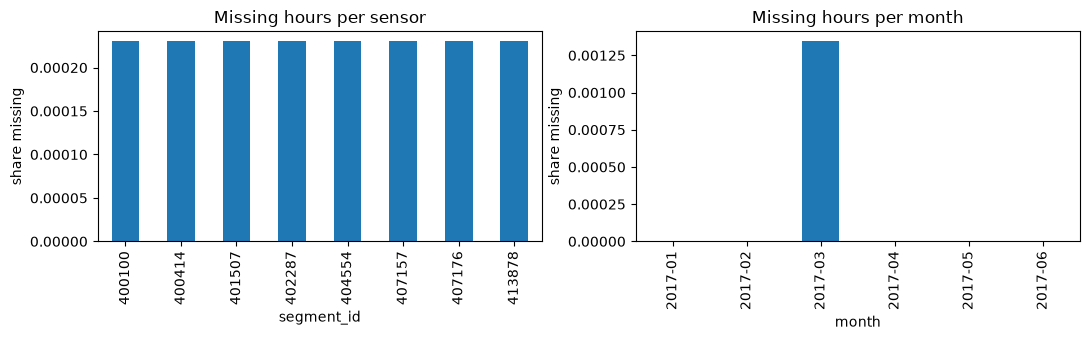

In [17]:
miss_sensor = hourly.groupby("segment_id")["speed_kmh"].apply(lambda s: s.isna().mean()).rename("missing_rate")
miss_sensor.to_csv(OUT / "missing_per_sensor.csv")
hourly["month"] = hourly["timestamp"].dt.to_period("M").astype(str)
miss_month = hourly.groupby("month")["speed_kmh"].apply(lambda s: s.isna().mean()).rename("missing_rate")
miss_month.to_csv(OUT / "missing_per_month.csv")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
miss_sensor.plot.bar(ax=ax[0], title="Missing hours per sensor"); ax[0].set_ylabel("share missing")
miss_month.plot.bar(ax=ax[1], title="Missing hours per month"); ax[1].set_ylabel("share missing")
plt.tight_layout(); plt.savefig(OUT / "missing_rates.png", dpi=150); plt.show()

### B3. Flat runs longer than 6 hours (stuck sensors)

In [18]:
def longest_flat_run(s: pd.Series) -> int:
    s = s.dropna()
    if s.empty:
        return 0
    groups = s.ne(s.shift()).cumsum()
    return int(s.groupby(groups).size().max())

flat = hourly.sort_values("timestamp").groupby("segment_id")["speed_kmh"].apply(longest_flat_run).rename("longest_flat_run_h")
flat.to_csv(OUT / "flat_runs.csv")
print("Sensors with a flat run over 6 hours:", int((flat > 6).sum()))
flat

Sensors with a flat run over 6 hours: 1


segment_id
400100    24
400414     2
401507     2
402287     2
404554     2
407157     2
407176     2
413878     3
Name: longest_flat_run_h, dtype: int64

### B4. Duplicates

In [19]:
dups = int(hourly.duplicated(["timestamp", "segment_id"]).sum())
print("Duplicated (timestamp, segment_id) rows:", dups)
assert dups == 0

Duplicated (timestamp, segment_id) rows: 0


### B5. Timezone check: do the slow hours match known rush hours?

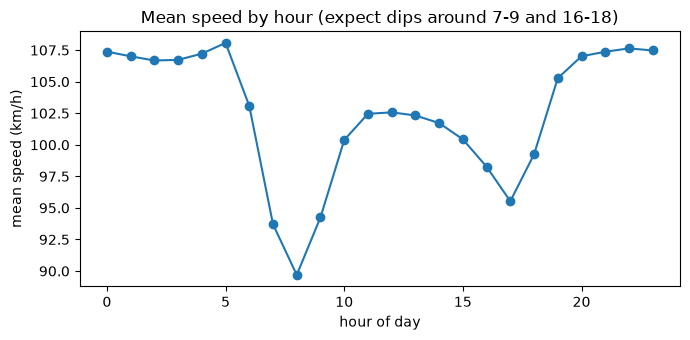

Slowest three hours: [8, 7, 9]


In [20]:
by_hour = hourly.groupby(hourly["timestamp"].dt.hour)["speed_kmh"].mean()
fig, ax = plt.subplots(figsize=(7, 3.5))
by_hour.plot(ax=ax, marker="o"); ax.set_xlabel("hour of day"); ax.set_ylabel("mean speed (km/h)")
ax.set_title("Mean speed by hour (expect dips around 7-9 and 16-18)")
plt.tight_layout(); plt.savefig(OUT / "speed_by_hour.png", dpi=150); plt.show()
print("Slowest three hours:", by_hour.nsmallest(3).index.tolist())

### B6. Speed distribution per sensor

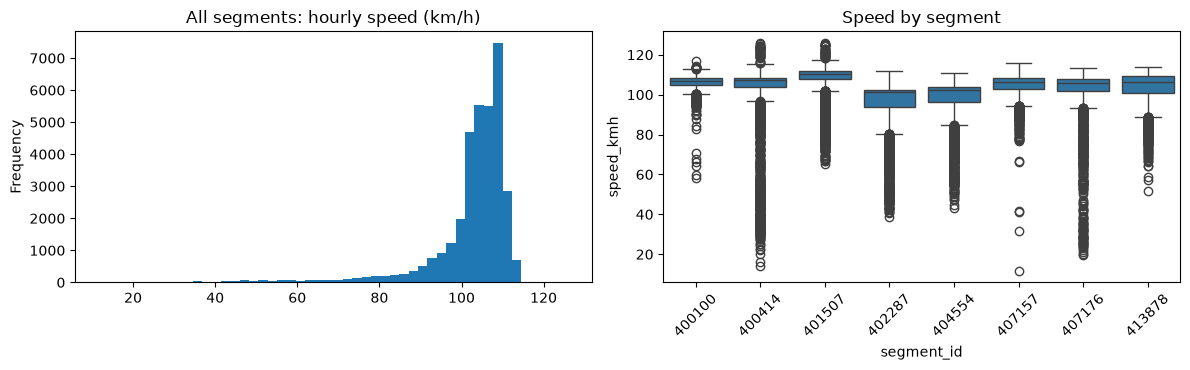

count    34744.0
mean       102.6
std         10.8
min         11.6
25%        101.5
50%        105.0
75%        108.4
max        126.0
Name: speed_kmh, dtype: float64

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
hourly["speed_kmh"].plot.hist(bins=50, ax=ax[0], title="All segments: hourly speed (km/h)")
sns.boxplot(data=hourly, x="segment_id", y="speed_kmh", ax=ax[1])
ax[1].set_title("Speed by segment"); ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(OUT / "speed_distribution.png", dpi=150); plt.show()
hourly["speed_kmh"].describe().round(1)

### B7. Speed by hour and weekday (heatmap)

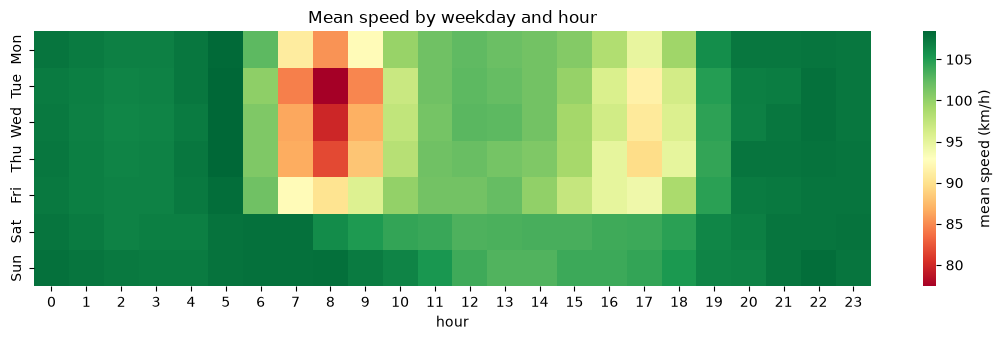

In [22]:
grid = (hourly.assign(dow=hourly["timestamp"].dt.dayofweek, hour=hourly["timestamp"].dt.hour)
              .pivot_table(index="dow", columns="hour", values="speed_kmh", aggfunc="mean"))
grid.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, ax = plt.subplots(figsize=(11, 3.5))
sns.heatmap(grid, cmap="RdYlGn", ax=ax, cbar_kws={"label": "mean speed (km/h)"})
ax.set_title("Mean speed by weekday and hour")
plt.tight_layout(); plt.savefig(OUT / "speed_heatmap.png", dpi=150); plt.show()

### B8. Weather coverage after the merge and neighbour feature coverage

In [23]:
cols = ["temperature", "humidity", "precipitation", "neighbour_speed_t", "is_holiday"]
cov = hourly[cols].isna().sum().rename("nan_count")
cov.to_csv(OUT / "feature_nan_counts.csv")
print(cov)
print("Holiday hours:", int(hourly["is_holiday"].sum()), "| rainy hours:", int((hourly["precipitation"] > 0).sum()))

temperature          0
humidity             0
precipitation        0
neighbour_speed_t    8
is_holiday           0
Name: nan_count, dtype: int64
Holiday hours: 1344 | rainy hours: 5488


### B9. Summary table for the website

In [24]:
summary = pd.DataFrame({
    "segments": [hourly["segment_id"].nunique()],
    "start": [hourly["timestamp"].min()],
    "end": [hourly["timestamp"].max()],
    "rows": [len(hourly)],
    "missing_rate": [round(float(hourly["speed_kmh"].isna().mean()), 4)],
})
summary.to_csv(OUT / "summary.csv", index=False)
summary

,segments,start,end,rows,missing_rate
0,8,2017-01-01,2017-06-30 23:00:00,34752,0.0002


## Part B plots (Day 3)
The notebook's first cell already moves to the repository root, so paths here are relative to the root (not `../`).

### B0. Setup

In [25]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
OUT = "results/data_quality/"; os.makedirs(OUT, exist_ok=True)
h = pd.read_parquet("data/processed/hourly.parquet")
h["month"] = h["timestamp"].dt.to_period("M").astype(str)
h["hour"] = h["timestamp"].dt.hour; h["dow"] = h["timestamp"].dt.dayofweek
print(h.shape, "| segments:", h["segment_id"].nunique())

(34752, 11) | segments: 8


### B1. Coverage per sensor

In [26]:
cov = h.groupby("segment_id").agg(start=("timestamp","min"), end=("timestamp","max"),
        rows=("timestamp","size"), missing=("speed_kmh", lambda s: s.isna().mean()))
cov.to_csv(OUT+"coverage_per_sensor.csv"); cov

,start,end,rows,missing
segment_id,,,,
400100,2017-01-01,2017-06-30 23:00:00,4344,0.00023
400414,2017-01-01,2017-06-30 23:00:00,4344,0.00023
401507,2017-01-01,2017-06-30 23:00:00,4344,0.00023
402287,2017-01-01,2017-06-30 23:00:00,4344,0.00023
404554,2017-01-01,2017-06-30 23:00:00,4344,0.00023
407157,2017-01-01,2017-06-30 23:00:00,4344,0.00023
407176,2017-01-01,2017-06-30 23:00:00,4344,0.00023
413878,2017-01-01,2017-06-30 23:00:00,4344,0.00023


**Saw:** 8 segments, each 4,344 hourly rows (181 days × 24), 2017-01-01 00:00 to 2017-06-30 23:00, missing rate 0.00023 (= 1 hour out of 4,344) for every segment.

**Means:** coverage is essentially complete. The same single hour is missing everywhere, which points to a calendar cause (see B2), not to sensor faults.

### B2. Missing per month

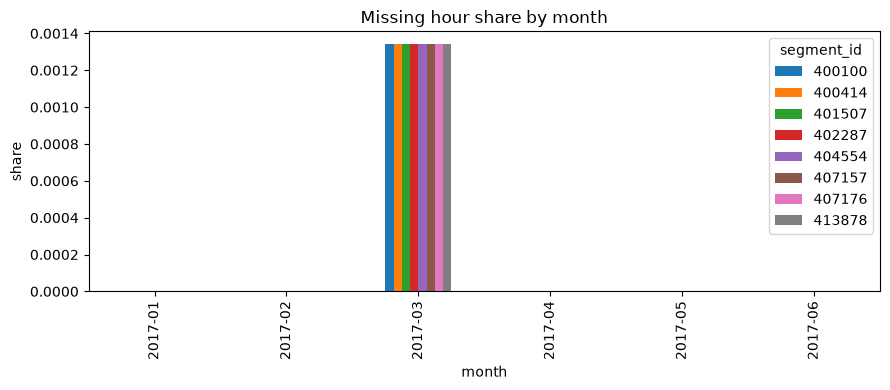

In [27]:
mm = h.assign(miss=h["speed_kmh"].isna()).pivot_table(index="segment_id", columns="month", values="miss", aggfunc="mean")
mm.to_csv(OUT+"missing_by_month.csv")
ax = mm.T.plot(kind="bar", figsize=(9,4), title="Missing hour share by month"); ax.set_ylabel("share")
plt.tight_layout(); plt.savefig(OUT+"missing_by_month.png", dpi=150); plt.show()

**Saw:** all months are 0 except March, where every segment has 0.0013 (1 of 744 hours). There is no tall June bar.

**Means:** the missing hour is the 2017-03-12 02:00 DST spring-forward hour that does not exist in local time. The 2017-06-15 feed outage was one 5-minute moment, so the hourly average (needs 9 of 12 readings) absorbed it.

### B3. Missingness over time

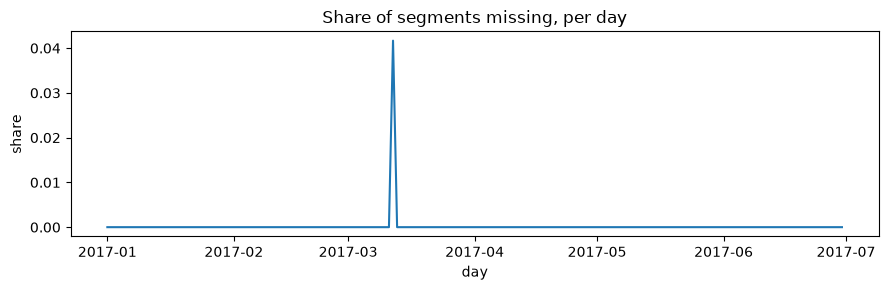

In [28]:
d = h.assign(miss=h["speed_kmh"].isna(), day=h["timestamp"].dt.date).groupby("day")["miss"].mean()
ax = d.plot(figsize=(9,3), title="Share of segments missing, per day"); ax.set_ylabel("share")
plt.tight_layout(); plt.savefig(OUT+"missing_over_time.png", dpi=150); plt.show()

**Saw:** flat at 0 for 180 days with a single small spike (about 0.04) on 2017-03-12.

**Means:** that spike is 1 missing hour out of 24 on the DST day. No outage periods remain in the hourly table, so the models need no gap handling beyond that one hour.

### B4. Flat runs and duplicates

In [29]:
def longest_flat(s):
    s = s.dropna(); r = (s != s.shift()).cumsum()
    return int(s.groupby(r).size().max())
flat = h.groupby("segment_id")["speed_kmh"].apply(longest_flat)
flat.to_csv(OUT+"longest_flat_run.csv"); print(flat)
print("duplicates:", h.duplicated(["timestamp","segment_id"]).sum())

segment_id
400100    24
400414     2
401507     2
402287     2
404554     2
407157     2
407176     2
413878     3
Name: speed_kmh, dtype: int64
duplicates: 0


**Saw:** duplicates 0. Seven segments have a longest flat run of 2-3 hours, but segment 400100 has 24 identical hourly values (109.6 km/h).

**Means:** 400100 is a stuck sensor on some days. The long runs are 2017-04-20 and 2017-05-18 (24 h each, 109.6 km/h), 2017-05-30 and 2017-06-06 (12 h each, 107.7 km/h), plus 10-hour runs on 04-19 and 05-17 (105.6 km/h). The raw 5-minute data repeat 68.1 mph, so this is a frozen feed, not real traffic. Kept as is and noted as a limitation; errors for 400100 on those days should be read with care.

### B5. Speed distribution

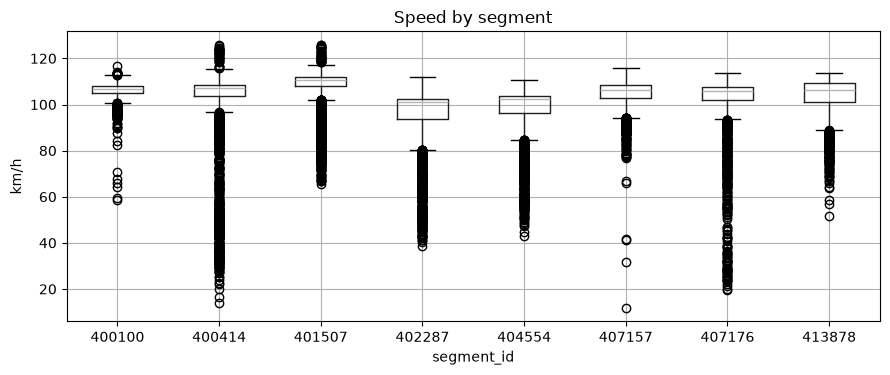

In [30]:
ax = h.boxplot(column="speed_kmh", by="segment_id", figsize=(9,4)); plt.suptitle("")
ax.set_title("Speed by segment"); ax.set_ylabel("km/h")
plt.tight_layout(); plt.savefig(OUT+"speed_boxplot.png", dpi=150); plt.show()

**Saw:** medians sit at 101-110 km/h with tight boxes; each segment has a tail of low outliers (minimum 11.6 to 65 km/h).

**Means:** free-flow traffic is near the speed limit and the low outliers are congestion. Segments 402287 and 404554 are slowest and 400414 has the widest spread, so they are the harder ones to predict.

### B6. Hour × weekday heatmap and timezone check

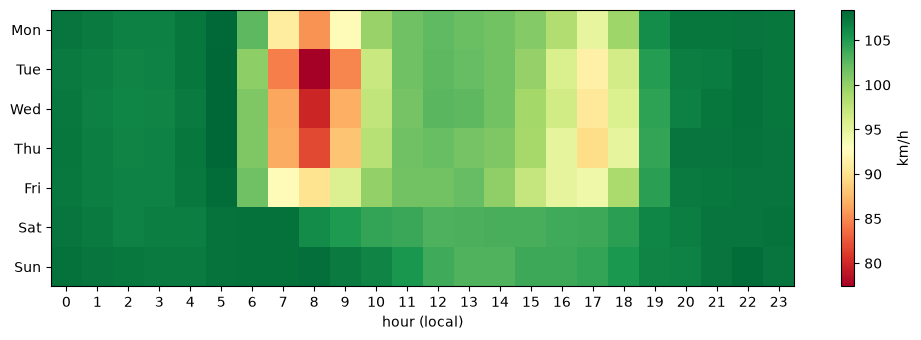

In [31]:
hm = h.pivot_table(index="dow", columns="hour", values="speed_kmh", aggfunc="mean")
fig, ax = plt.subplots(figsize=(10,3.5)); im = ax.imshow(hm.values, aspect="auto", cmap="RdYlGn")
ax.set_yticks(range(7)); ax.set_yticklabels(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"])
ax.set_xticks(range(24)); ax.set_xlabel("hour (local)"); fig.colorbar(im, label="km/h")
plt.tight_layout(); plt.savefig(OUT+"hour_dow_heatmap.png", dpi=150); plt.show()

**Saw:** Mon-Fri are slow at 7-9 (lowest about 77-85 km/h at 08:00 on Tue-Thu) and again at 16-18 (about 90 km/h). Nights and weekends stay near 107 km/h.

**Means:** the slow hours match real Bay Area rush hours, so the timestamps really are local time (no 7-8 hour shift). Hour and weekday are therefore strong features.

### B7. Weather coverage

In [32]:
w = h[["temperature","humidity","precipitation"]].isna().sum(); w.to_csv(OUT+"weather_nan.csv"); print(w)

temperature      0
humidity         0
precipitation    0
dtype: int64


**Saw:** 0 missing values in temperature, humidity and precipitation.

**Means:** the weather merge is complete, so no weather imputation is needed.